<a href="https://colab.research.google.com/github/sardorbekmuminov/esc50-sound-classifier/blob/main/esc50_sound_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔊 Environmental Sound Classification with Transfer Learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sardorbekmuminov/esc50-sound-classifier/blob/main/esc50_sound_classifier.ipynb)
![Python](https://img.shields.io/badge/Python-3.10+-blue)
![PyTorch](https://img.shields.io/badge/PyTorch-timm-red)

**Goal:** recognize everyday sounds (dog bark, rain, siren, keyboard typing, ...) from an audio clip and report the model's **confidence** for each prediction.

**Approach:** convert audio to log-mel spectrograms (images of sound) and classify them with an ImageNet-pretrained **ResNet18**. Three training strategies are compared:

| # | Strategy | What is trained |
|---|----------|-----------------|
| A | From scratch | all weights, random init |
| B | Feature extraction | only the final classifier layer (backbone frozen) |
| C | Fine-tuning | all weights, starting from ImageNet weights |

The best model is wrapped in an interactive **Gradio web app**: upload or record a sound, and see the top predictions with confidence scores.

**Dataset:** [ESC-50](https://github.com/karolpiczak/ESC-50) — 2,000 five-second clips, 50 classes, 5 predefined folds.

**Contents**
1. Setup
2. Configuration
3. Dataset
4. Audio preprocessing (log-mel spectrogram)
5. Feature tensors and train / validation / test split
6. Training utilities
7. Experiment A — training from scratch
8. Experiment B — feature extraction (frozen backbone)
9. Experiment C — fine-tuning
10. Model comparison
11. Per-class analysis
12. Saving the model
13. Inference on new audio
14. Interactive web demo
15. Permanent deployment (Hugging Face Spaces)
16. Conclusions and next steps

## 1. Setup
Install dependencies and download the dataset. (On Google Colab `torch` is preinstalled; a GPU runtime is recommended: *Runtime → Change runtime type → T4 GPU*.)

In [1]:
!pip install -q timm librosa gradio soundfile
!git clone --depth 1 https://github.com/karolpiczak/ESC-50 2>/dev/null || echo "ESC-50 already downloaded"

## 2. Configuration
All hyperparameters live in one place so experiments are easy to reproduce.

In [2]:
import json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import timm
import librosa

SEED = 42
ROOT = Path("ESC-50")

# audio / spectrogram
SR, DURATION = 22050, 5
N_SAMPLES = SR * DURATION
N_FFT, HOP, N_MELS = 1024, 512, 128

# training
EPOCHS, BATCH_SIZE = 15, 32
LR = {"scratch": 1e-3, "feature_extraction": 1e-2, "fine_tuning": 3e-4}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
print("Device:", DEVICE)

Device: cuda


## 3. Dataset
ESC-50 ships with a metadata file. Each clip belongs to one of **5 folds**; we use the official folds to avoid leakage between clips cut from the same source recording:

- folds 1–3 → **train** (1,200 clips)
- fold 4 → **validation** (400 clips)
- fold 5 → **test** (400 clips)

In [3]:
df = pd.read_csv(ROOT / "meta" / "esc50.csv")
print(f"{len(df)} clips | clips per fold: {df.fold.value_counts().sort_index().tolist()}")
df.head()

2000 clips | clips per fold: [400, 400, 400, 400, 400]


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [4]:
CLASSES = sorted(df.category.unique())
NUM_CLASSES = len(CLASSES)
print(NUM_CLASSES, "classes:")
print(CLASSES)

y = torch.tensor([CLASSES.index(c) for c in df.category])
print("clips per class (should be 40 each):", y.bincount().unique().tolist())

50 classes:
['airplane', 'breathing', 'brushing_teeth', 'can_opening', 'car_horn', 'cat', 'chainsaw', 'chirping_birds', 'church_bells', 'clapping', 'clock_alarm', 'clock_tick', 'coughing', 'cow', 'crackling_fire', 'crickets', 'crow', 'crying_baby', 'dog', 'door_wood_creaks', 'door_wood_knock', 'drinking_sipping', 'engine', 'fireworks', 'footsteps', 'frog', 'glass_breaking', 'hand_saw', 'helicopter', 'hen', 'insects', 'keyboard_typing', 'laughing', 'mouse_click', 'pig', 'pouring_water', 'rain', 'rooster', 'sea_waves', 'sheep', 'siren', 'sneezing', 'snoring', 'thunderstorm', 'toilet_flush', 'train', 'vacuum_cleaner', 'washing_machine', 'water_drops', 'wind']
clips per class (should be 40 each): [40]


## 4. Audio preprocessing: log-mel spectrogram
A neural network cannot "listen" to a raw waveform easily, but it can look at a **mel spectrogram** — a picture where the x-axis is time, the y-axis is frequency (on a perceptual mel scale) and the colour is loudness. This lets us reuse powerful image models.

Steps: load audio at 22.05 kHz → pad/trim to exactly 5 s → mel spectrogram (128 bands) → convert power to decibels → scale to roughly [-2, 2].

In [5]:
def load_audio(path):
    sig, _ = librosa.load(path, sr=SR, mono=True)
    return sig

def fix_length(sig):
    """Pad with silence or trim so every clip is exactly 5 seconds."""
    if len(sig) < N_SAMPLES:
        sig = np.pad(sig, (0, N_SAMPLES - len(sig)))
    return sig[:N_SAMPLES]

def to_mel(sig):
    m = librosa.feature.melspectrogram(y=sig, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    db = librosa.power_to_db(m, ref=np.max)
    return ((db + 40) / 20).astype(np.float32)

def mel(path):
    return to_mel(fix_length(load_audio(path)))

example = df.iloc[0]
img = mel(ROOT / "audio" / example.filename)
print("Spectrogram shape (mel bands x time frames):", img.shape)

Spectrogram shape (mel bands x time frames): (128, 216)


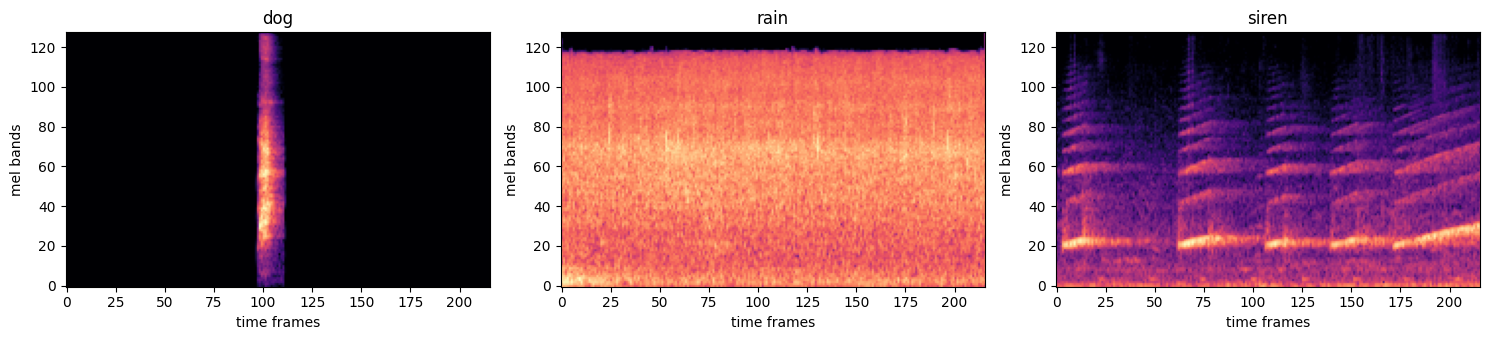

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, cat in zip(axes, ["dog", "rain", "siren"]):
    row = df[df.category == cat].iloc[0]
    ax.imshow(mel(ROOT / "audio" / row.filename), origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"{cat}"); ax.set_xlabel("time frames"); ax.set_ylabel("mel bands")
plt.tight_layout(); plt.show()

## 5. Feature tensors and train / validation / test split
All 2,000 clips are converted once and kept in memory as a single-channel tensor. Batches are moved to the GPU on demand, so memory use stays low.

In [7]:
from tqdm.auto import tqdm

X = torch.from_numpy(np.stack([mel(ROOT / "audio" / f) for f in tqdm(df.filename)]))[:, None]
print("X:", tuple(X.shape), "| y:", tuple(y.shape))

  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 1, 128, 216) | y: (2000,)


In [8]:
fold = df.fold.values
tr, va, te = fold <= 3, fold == 4, fold == 5

Xtr, ytr = X[tr], y[tr]
Xva, yva = X[va], y[va]
Xte, yte = X[te], y[te]
print(f"train={len(Xtr)}  val={len(Xva)}  test={len(Xte)}")

train=1200  val=400  test=400


## 6. Training utilities
- `evaluate` — loss and accuracy on a dataset (batched, no gradients)
- `fit` — Adam training loop; after training it **restores the weights with the best validation accuracy**
- `make_model` — a `timm` ResNet18 with a 1-channel input (the pretrained first conv layer is adapted automatically) and a 50-class output layer

In [9]:
@torch.no_grad()
def evaluate(model, X, y, bs=128):
    model.eval()
    total_loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        xb, yb = X[i:i + bs].to(DEVICE), y[i:i + bs].to(DEVICE)
        out = model(xb)
        total_loss += F.cross_entropy(out, yb, reduction="sum").item()
        correct += (out.argmax(1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)


def fit(model, params, lr, epochs=EPOCHS, bs=BATCH_SIZE):
    opt = torch.optim.Adam(params, lr=lr)
    history, best_acc, best_state = [], -1.0, None
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr))
        running = 0.0
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            xb, yb = Xtr[idx].to(DEVICE), ytr[idx].to(DEVICE)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            running += loss.item() * len(idx)
        val_loss, val_acc = evaluate(model, Xva, yva)
        history.append({"epoch": ep, "train_loss": running / len(Xtr),
                        "val_loss": val_loss, "val_acc": val_acc})
        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"epoch {ep:2d}/{epochs} | train loss {running/len(Xtr):.3f} | "
              f"val loss {val_loss:.3f} | val acc {val_acc:.3f}")
    model.load_state_dict(best_state)          # keep the best epoch
    return pd.DataFrame(history)


def make_model(pretrained):
    return timm.create_model("resnet18", pretrained=pretrained,
                             num_classes=NUM_CLASSES, in_chans=1).to(DEVICE)

histories = {}

## 7. Experiment A — training from scratch
Random initial weights: the network must learn everything (edges, textures, *and* sound patterns) from only 1,200 clips. This is the baseline.

In [10]:
seed_everything()
scratch = make_model(pretrained=False)
histories["From scratch"] = fit(scratch, scratch.parameters(), lr=LR["scratch"])

epoch  1/15 | train loss 3.619 | val loss 3.459 | val acc 0.098
epoch  2/15 | train loss 2.947 | val loss 2.983 | val acc 0.198
epoch  3/15 | train loss 2.527 | val loss 3.038 | val acc 0.217
epoch  4/15 | train loss 2.153 | val loss 2.438 | val acc 0.357
epoch  5/15 | train loss 1.777 | val loss 2.200 | val acc 0.375
epoch  6/15 | train loss 1.528 | val loss 2.023 | val acc 0.405
epoch  7/15 | train loss 1.266 | val loss 1.764 | val acc 0.482
epoch  8/15 | train loss 1.083 | val loss 2.101 | val acc 0.435
epoch  9/15 | train loss 0.890 | val loss 1.603 | val acc 0.542
epoch 10/15 | train loss 0.663 | val loss 1.475 | val acc 0.557
epoch 11/15 | train loss 0.489 | val loss 1.364 | val acc 0.593
epoch 12/15 | train loss 0.423 | val loss 1.549 | val acc 0.568
epoch 13/15 | train loss 0.304 | val loss 1.416 | val acc 0.580
epoch 14/15 | train loss 0.242 | val loss 1.342 | val acc 0.610
epoch 15/15 | train loss 0.163 | val loss 1.348 | val acc 0.632


## 8. Experiment B — feature extraction (frozen backbone)
The ImageNet-pretrained backbone is **frozen**; only the new classification layer (`fc`) is trained. Fast and cheap, but the backbone has never seen spectrograms.

In [11]:
seed_everything()
frozen = make_model(pretrained=True)
for p in frozen.parameters():
    p.requires_grad = False
for p in frozen.fc.parameters():
    p.requires_grad = True

trainable = sum(p.numel() for p in frozen.parameters() if p.requires_grad)
print(f"Trainable parameters: {trainable:,}")
histories["Feature extraction"] = fit(frozen, frozen.fc.parameters(), lr=LR["feature_extraction"])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Trainable parameters: 25,650
epoch  1/15 | train loss 3.465 | val loss 2.762 | val acc 0.287
epoch  2/15 | train loss 1.836 | val loss 1.968 | val acc 0.470
epoch  3/15 | train loss 1.309 | val loss 1.740 | val acc 0.522
epoch  4/15 | train loss 1.011 | val loss 1.654 | val acc 0.537
epoch  5/15 | train loss 0.829 | val loss 1.581 | val acc 0.552
epoch  6/15 | train loss 0.714 | val loss 1.585 | val acc 0.540
epoch  7/15 | train loss 0.585 | val loss 1.566 | val acc 0.560
epoch  8/15 | train loss 0.556 | val loss 1.539 | val acc 0.578
epoch  9/15 | train loss 0.514 | val loss 1.523 | val acc 0.568
epoch 10/15 | train loss 0.455 | val loss 1.511 | val acc 0.557
epoch 11/15 | train loss 0.396 | val loss 1.466 | val acc 0.575
epoch 12/15 | train loss 0.365 | val loss 1.569 | val acc 0.550
epoch 13/15 | train loss 0.333 | val loss 1.493 | val acc 0.560
epoch 14/15 | train loss 0.309 | val loss 1.525 | val acc 0.573
epoch 15/15 | train loss 0.274 | val loss 1.485 | val acc 0.585


## 9. Experiment C — fine-tuning
Start from ImageNet weights and update **all** layers with a small learning rate, so the pretrained features adapt to spectrograms without being destroyed.

In [12]:
seed_everything()
ft = make_model(pretrained=True)
histories["Fine-tuning"] = fit(ft, ft.parameters(), lr=LR["fine_tuning"])

epoch  1/15 | train loss 3.824 | val loss 3.743 | val acc 0.133
epoch  2/15 | train loss 3.423 | val loss 3.270 | val acc 0.320
epoch  3/15 | train loss 2.877 | val loss 2.700 | val acc 0.460
epoch  4/15 | train loss 2.232 | val loss 2.161 | val acc 0.565
epoch  5/15 | train loss 1.646 | val loss 1.701 | val acc 0.595
epoch  6/15 | train loss 1.183 | val loss 1.416 | val acc 0.662
epoch  7/15 | train loss 0.827 | val loss 1.210 | val acc 0.703
epoch  8/15 | train loss 0.629 | val loss 1.035 | val acc 0.752
epoch  9/15 | train loss 0.460 | val loss 0.963 | val acc 0.745
epoch 10/15 | train loss 0.332 | val loss 0.888 | val acc 0.752
epoch 11/15 | train loss 0.245 | val loss 0.849 | val acc 0.775
epoch 12/15 | train loss 0.205 | val loss 0.818 | val acc 0.760
epoch 13/15 | train loss 0.142 | val loss 0.798 | val acc 0.782
epoch 14/15 | train loss 0.111 | val loss 0.758 | val acc 0.792
epoch 15/15 | train loss 0.084 | val loss 0.761 | val acc 0.782


## 10. Model comparison
Validation accuracy per epoch, and final accuracy on the **held-out test fold** (never used for model selection).

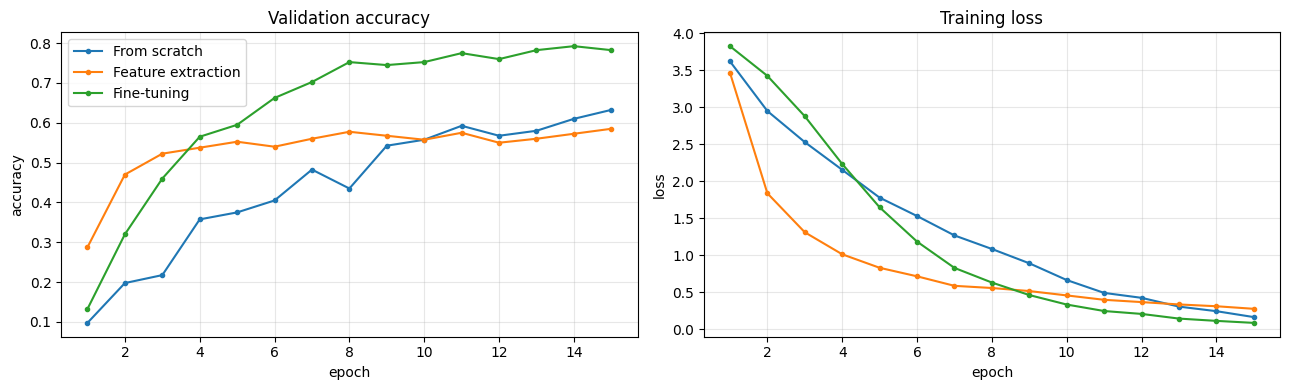

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories.items():
    axes[0].plot(h.epoch, h.val_acc, marker="o", ms=3, label=name)
    axes[1].plot(h.epoch, h.train_loss, marker="o", ms=3, label=name)
axes[0].set(title="Validation accuracy", xlabel="epoch", ylabel="accuracy"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].set(title="Training loss", xlabel="epoch", ylabel="loss"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [14]:
models = {"From scratch": scratch, "Feature extraction": frozen, "Fine-tuning": ft}
rows = []
for name, m in models.items():
    _, test_acc = evaluate(m, Xte, yte)
    rows.append({"Strategy": name,
                 "Best val acc": round(histories[name].val_acc.max(), 3),
                 "Test acc": round(test_acc, 3)})
results = pd.DataFrame(rows).set_index("Strategy")
results

,Best val acc,Test acc
Strategy,,
From scratch,0.632,0.562
Feature extraction,0.585,0.552
Fine-tuning,0.792,0.713


## 11. Per-class analysis (fine-tuned model)
Which sounds are easy, and which does the model confuse?

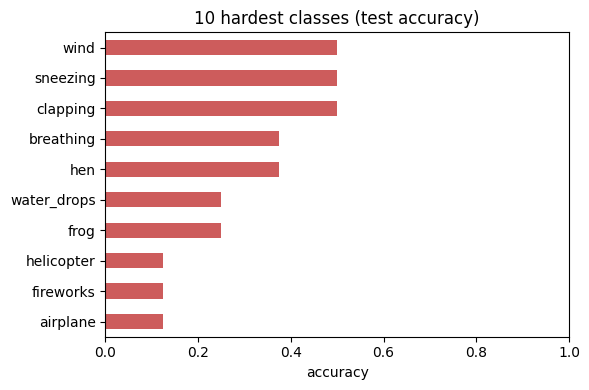

Easiest classes: {'rain': 1.0, 'sheep': 1.0, 'pouring_water': 1.0, 'snoring': 1.0, 'thunderstorm': 1.0}


In [15]:
@torch.no_grad()
def predict_labels(model, X, bs=128):
    model.eval()
    return torch.cat([model(X[i:i + bs].to(DEVICE)).argmax(1).cpu() for i in range(0, len(X), bs)])

pred = predict_labels(ft, Xte)
per_class = pd.Series({c: (pred[yte == i] == i).float().mean().item() for i, c in enumerate(CLASSES)})
per_class = per_class.sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
per_class.head(10).plot.barh(ax=ax, color="indianred")
ax.set(title="10 hardest classes (test accuracy)", xlabel="accuracy"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()
print("Easiest classes:", per_class.tail(5).round(2).to_dict())

## 12. Saving the model
The weights and the class list are saved so the web app (and anyone else) can load them without retraining.

In [16]:
torch.save({k: v.cpu() for k, v in ft.state_dict().items()}, "fine_tuned_resnet18.pt")
json.dump(CLASSES, open("classes.json", "w"))
print("Saved: fine_tuned_resnet18.pt, classes.json")

Saved: fine_tuned_resnet18.pt, classes.json


## 13. Inference on new audio
`predict` accepts **any audio file** (wav, mp3, m4a, ogg, ...). Clips longer than 5 s are split into 5-second windows and the probabilities are averaged. The output is the list of most likely classes with their **confidence** (softmax probability).

In [17]:
@torch.no_grad()
def predict_all(path, model=ft):
    """Return {class: probability} for an audio file of any length."""
    sig = load_audio(path)
    chunks = [sig[i:i + N_SAMPLES] for i in range(0, max(len(sig), 1), N_SAMPLES)]
    if len(chunks) > 1 and len(chunks[-1]) < SR:     # drop a tiny trailing chunk
        chunks = chunks[:-1]
    x = torch.from_numpy(np.stack([to_mel(fix_length(c)) for c in chunks]))[:, None].to(DEVICE)
    model.eval()
    probs = model(x).softmax(1).mean(0).cpu()
    return {c: float(p) for c, p in zip(CLASSES, probs)}


def predict(path, top_k=5, model=ft):
    probs = predict_all(path, model)
    return sorted(probs.items(), key=lambda kv: -kv[1])[:top_k]


# sanity check on a clip from the held-out test fold
sample = df[te].sample(1, random_state=1).iloc[0]
print("True label:", sample.category)
for name, p in predict(ROOT / "audio" / sample.filename):
    print(f"  {name:<18} {p:6.1%}")

True label: sheep
  sheep               48.6%
  chainsaw            24.4%
  crying_baby          5.5%
  frog                 5.2%
  crow                 4.1%


**Try your own audio on Colab:** upload a file in the left sidebar (📁) and run
`predict("/content/your_file.m4a")`.

## 14. Interactive web demo (Gradio)
Run the cell below and open the **public link** it prints (valid ~72 hours) to try the classifier in the browser: upload a file or record with your microphone, and the app shows the top-5 predictions with their confidence.

In [18]:
import gradio as gr

def classify(audio_path):
    if audio_path is None:
        return None
    return predict_all(audio_path)

example_files = [str(ROOT / "audio" / f) for f in df[te].filename.sample(3, random_state=0)]

demo = gr.Interface(
    fn=classify,
    inputs=gr.Audio(sources=["upload", "microphone"], type="filepath", label="Audio (upload or record)"),
    outputs=gr.Label(num_top_classes=5, label="Top-5 predictions (confidence)"),
    examples=example_files,
    cache_examples=False,
    title="Environmental Sound Classifier (ESC-50)",
    description="ResNet18 fine-tuned on log-mel spectrograms. Recognizes 50 everyday sound classes "
                "(dog, rain, siren, keyboard typing, ...). Audio longer than 5 s is split into windows and averaged.",
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9501bee13f724e15cb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 15. Permanent deployment (Hugging Face Spaces)
The Colab link expires. For a **permanent public demo** to put in your GitHub README:

1. Create a free account at [huggingface.co](https://huggingface.co) → *New Space* → SDK: **Gradio**.
2. Upload these four files: `app.py`, `requirements.txt`, `fine_tuned_resnet18.pt`, `classes.json`.
3. The Space builds automatically and gives you a permanent URL like `https://huggingface.co/spaces/<username>/esc50-sound-classifier`.

The cells below generate `app.py` and `requirements.txt` for you.

In [19]:
%%writefile app.py
import json
import gradio as gr
import librosa
import numpy as np
import timm
import torch

SR, DURATION = 22050, 5
N_SAMPLES = SR * DURATION
N_FFT, HOP, N_MELS = 1024, 512, 128

CLASSES = json.load(open("classes.json"))
model = timm.create_model("resnet18", pretrained=False, num_classes=len(CLASSES), in_chans=1)
model.load_state_dict(torch.load("fine_tuned_resnet18.pt", map_location="cpu"))
model.eval()


def fix_length(sig):
    if len(sig) < N_SAMPLES:
        sig = np.pad(sig, (0, N_SAMPLES - len(sig)))
    return sig[:N_SAMPLES]


def to_mel(sig):
    m = librosa.feature.melspectrogram(y=sig, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    db = librosa.power_to_db(m, ref=np.max)
    return ((db + 40) / 20).astype(np.float32)


@torch.no_grad()
def classify(path):
    if path is None:
        return None
    sig, _ = librosa.load(path, sr=SR, mono=True)
    chunks = [sig[i:i + N_SAMPLES] for i in range(0, max(len(sig), 1), N_SAMPLES)]
    if len(chunks) > 1 and len(chunks[-1]) < SR:   # drop a tiny trailing chunk
        chunks = chunks[:-1]
    x = torch.from_numpy(np.stack([to_mel(fix_length(c)) for c in chunks]))[:, None]
    probs = model(x).softmax(1).mean(0)
    return {c: float(p) for c, p in zip(CLASSES, probs)}


demo = gr.Interface(
    fn=classify,
    inputs=gr.Audio(sources=["upload", "microphone"], type="filepath", label="Audio (upload or record)"),
    outputs=gr.Label(num_top_classes=5, label="Top-5 predictions (confidence)"),
    title="Environmental Sound Classifier (ESC-50)",
    description="ResNet18 fine-tuned on log-mel spectrograms. Recognizes 50 everyday sound classes "
                "(dog, rain, siren, keyboard typing, ...). Audio longer than 5 s is split into windows and averaged.",
)

if __name__ == "__main__":
    demo.launch()

Writing app.py


In [20]:
%%writefile requirements.txt
torch
torchaudio
timm
librosa
gradio
numpy
soundfile

Writing requirements.txt


## 16. Conclusions and next steps

**Takeaways**
- Treating audio as an image (log-mel spectrogram) lets us reuse ImageNet models for sound classification.
- Compare the three strategies in the table in Section 10: pretrained initialization typically beats training from scratch on a small dataset, and fine-tuning usually beats a frozen backbone.
- Using official dataset folds keeps the test score honest.

**Limitations**
- Only 50 fixed classes; a sound outside them will still be forced into one of the 50 (check the confidence score!).
- Clips are short and mostly clean; heavy background noise or overlapping sounds reduce accuracy.
- Only one run per strategy — results vary slightly between random seeds.

**Next steps**
- Data augmentation (SpecAugment, mixup, time shift, noise)
- Full 5-fold cross-validation and averaging over seeds
- Larger backbones or audio-pretrained models (e.g. AST, PANNs)
- Confidence threshold with an "unknown sound" option

**Credits:** dataset — Piczak, K. J. *ESC: Dataset for Environmental Sound Classification*, ACM Multimedia 2015 (licensed CC BY-NC, non-commercial use). Models — [timm](https://github.com/huggingface/pytorch-image-models).